Descargando archivo experimental...
Archivo descargado correctamente: Ag.yml

Contenido principal del archivo:
dict_keys(['REFERENCES', 'COMMENTS', 'DATA'])

Estructura DATA:
[{'type': 'tabulated nk', 'data': '0.1879 1.07 1.212\n0.1916 1.10 1.232\n0.1953 1.12 1.255\n0.1993 1.14 1.277\n0.2033 1.15 1.296\n0.2073 1.18 1.312\n0.2119 1.20 1.325\n0.2164 1.22 1.336\n0.2214 1.25 1.342\n0.2262 1.26 1.344\n0.2313 1.28 1.357\n0.2371 1.28 1.367\n0.2426 1.30 1.378\n0.2490 1.31 1.389\n0.2551 1.33 1.393\n0.2616 1.35 1.387\n0.2689 1.38 1.372\n0.2761 1.41 1.331\n0.2844 1.41 1.264\n0.2924 1.39 1.161\n0.3009 1.34 0.964\n0.3107 1.13 0.616\n0.3204 0.81 0.392\n0.3315 0.17 0.829\n0.3425 0.14 1.142\n0.3542 0.10 1.419\n0.3679 0.07 1.657\n0.3815 0.05 1.864\n0.3974 0.05 2.070\n0.4133 0.05 2.275\n0.4305 0.04 2.462\n0.4509 0.04 2.657\n0.4714 0.05 2.869\n0.4959 0.05 3.093\n0.5209 0.05 3.324\n0.5486 0.06 3.586\n0.5821 0.05 3.858\n0.6168 0.06 4.152\n0.6595 0.05 4.483\n0.7045 0.04 4.838\n0.7560 0.03 5.242\n0.8211 0.04

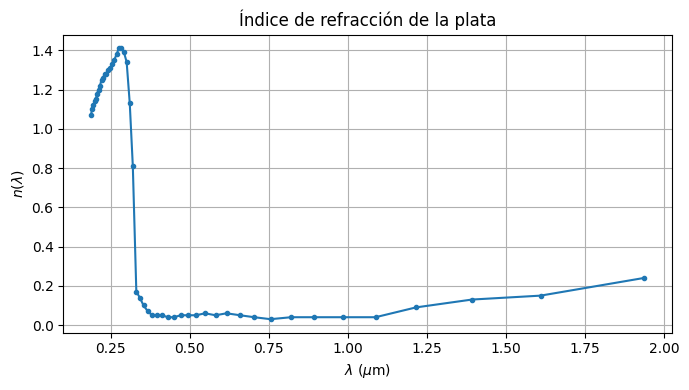

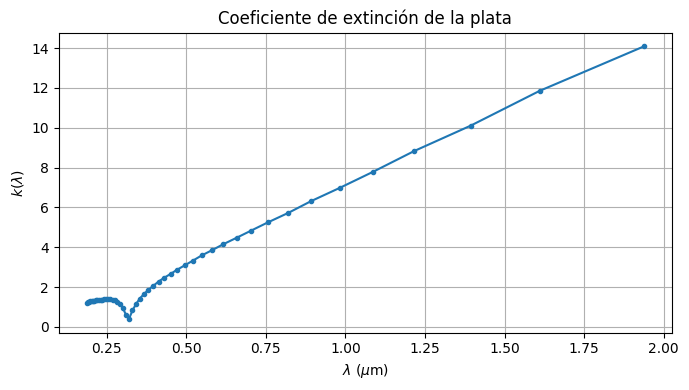

In [1]:
# -*- coding: utf-8 -*-
"""
Created on Wed Jul 29 18:34:13 2026

@author: UIS
"""

import requests
import yaml
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Descarga del archivo experimental Ag.yml
# Base de datos refractiveindex.info
# Datos de Johnson y Christy para plata
# ============================================================
url = "https://raw.githubusercontent.com/polyanskiy/refractiveindex.info-database/master/database/data/main/Ag/nk/Johnson.yml"
file_name = "Ag.yml"

print("Descargando archivo experimental...")
response = requests.get(url, timeout=30)

if response.status_code == 200:
    with open(file_name, "wb") as file:
        file.write(response.content)
    print("Archivo descargado correctamente:", file_name)
else:
    raise Exception("No fue posible descargar el archivo")

# ============================================================
# Lectura del archivo YAML
# ============================================================
with open(file_name, "r") as file:
    data = yaml.safe_load(file)

print("\nContenido principal del archivo:")
print(data.keys())

# ============================================================
# Extracción de datos experimentales
# ============================================================
print("\nEstructura DATA:")
print(data["DATA"])

raw_data = data["DATA"][0]["data"]

wavelength = []
n_values = []
k_values = []

for line in raw_data.split("\n"):
    if line.strip():
        values = line.split()
        wavelength.append(float(values[0]))
        n_values.append(float(values[1]))
        k_values.append(float(values[2]))

wavelength = np.array(wavelength)
n_values = np.array(n_values)
k_values = np.array(k_values)

print("\nNúmero de puntos experimentales:")
print(len(wavelength))

# ============================================================
# Guardar datos procesados
# ============================================================
output = np.column_stack((wavelength, n_values, k_values))

np.savetxt(
    "Ag_optical_data.dat",
    output,
    header="lambda (um) n(lambda) k(lambda)",
    fmt="%.8e"
)

print("\nArchivo generado: Ag_optical_data.dat")
# ============================================================
# Gráfica del índice de refracción
# ============================================================
plt.figure(figsize=(7, 4))
plt.plot(
    wavelength,
    n_values,
    marker="o",
    markersize=3
)
plt.xlabel(r"$\lambda$ ($\mu$m)")
plt.ylabel(r"$n(\lambda)$")
plt.title("Índice de refracción de la plata")
plt.grid()
plt.tight_layout()
plt.show()

# ============================================================
# Gráfica del coeficiente de extinción
# ============================================================
plt.figure(figsize=(7, 4))
plt.plot(
    wavelength,
    k_values,
    marker="o",
    markersize=3
)
plt.xlabel(r"$\lambda$ ($\mu$m)")
plt.ylabel(r"$k(\lambda)$")
plt.title("Coeficiente de extinción de la plata")
plt.grid()
plt.tight_layout()
plt.show()

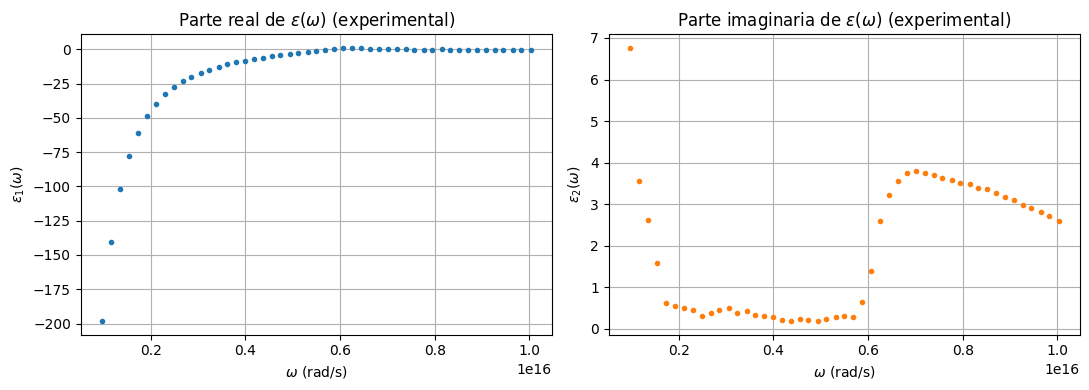

=== Punto 3: parametros del ajuste de Drude ===
eps_inf = 3.5821 +/- 0.2943
w_p     = 1.3893e+16 +/- 4.6703e+13 rad/s
gamma   = 3.1914e+13 +/- 6.7578e+12 rad/s


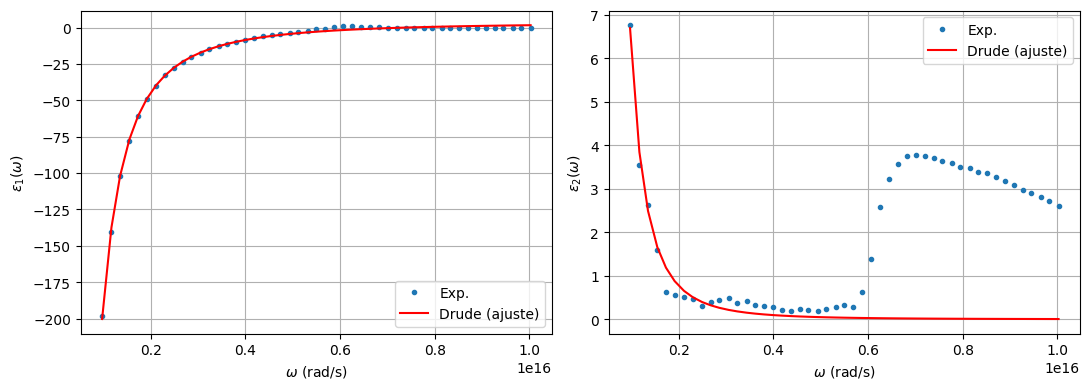


=== Punto 4: parametros fisicos ===
Frecuencia de plasma wp = 1.3893e+16 rad/s
Tiempo de relajacion tau = 3.1335e-14 s
Concentracion de portadores N = 6.0649e+28 m^-3  (6.0649e+22 cm^-3)

=== Punto 5: propiedades opticas (con d = 50 nm) ===
R  (min, max): 7.756505621022421e-05 0.9953172807309603
alpha (1/m) (min, max): 158624.78633220494 91831586.89155746
T  (min, max): 4.746795804710824e-05 0.9868385457905515


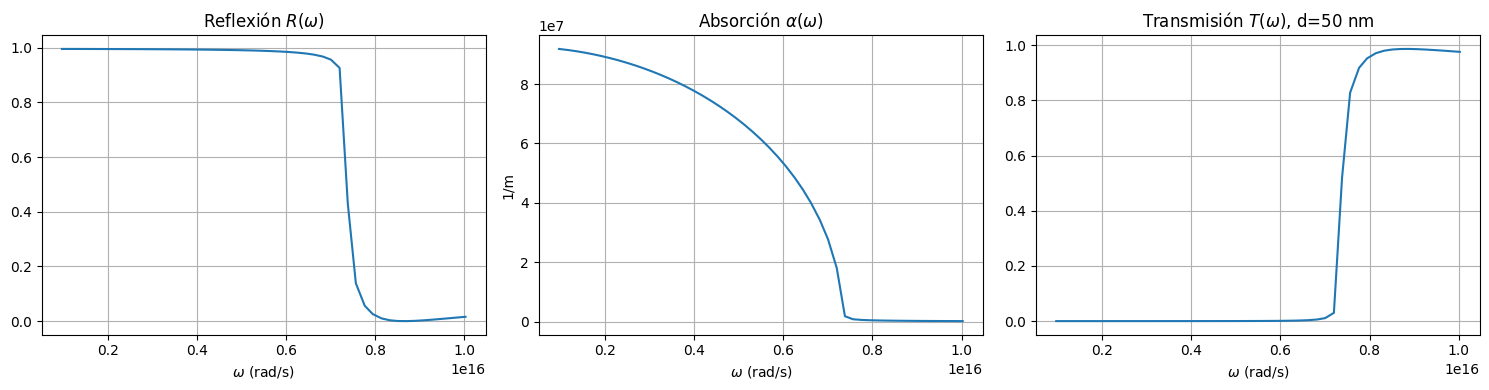

In [2]:
# -*- coding: utf-8 -*-
"""
Caso de estudio 3 - Extracción de propiedades ópticas y electrónicas de la plata
Cubre los 5 puntos de la sección 1.7 (Modelo computacional):
  1. Procesamiento de los datos experimentales
  2. Cálculo de la función dieléctrica
  3. Implementación del modelo electrónico (Drude)
  4. Determinación de parámetros físicos
  5. Cálculo de propiedades ópticas

@author: UIS
"""

import numpy as np
import scipy.optimize as OPT
import matplotlib.pyplot as plt

# ============================================================
# PUNTO 1: Procesamiento de los datos experimentales
# (continúa del script que descarga Ag.yml y genera Ag_optical_data.dat)
# ============================================================
c = 2.99792458e8                     # velocidad de la luz (m/s)
data = np.loadtxt("Ag_optical_data.dat")

wavelength_um = data[:, 0]
n = data[:, 1]
k = data[:, 2]

wavelength_m = wavelength_um * 1e-6
omega = (2 * np.pi * c) / wavelength_m     # rad/s

# ============================================================
# PUNTO 2: Cálculo de la función dieléctrica
#   eps(w) = eps1(w) + i*eps2(w)
# Este es un paso INDEPENDIENTE del ajuste: primero se obtiene
# la función dieléctrica experimental y se grafica tal cual,
# antes de introducir ningún modelo teórico.
# ============================================================
eps1_exp = n**2 - k**2
eps2_exp = 2 * n * k

fig0, axs0 = plt.subplots(1, 2, figsize=(11, 4))

axs0[0].plot(omega, eps1_exp, 'o', markersize=3, color='tab:blue')
axs0[0].set_xlabel(r'$\omega$ (rad/s)')
axs0[0].set_ylabel(r'$\varepsilon_1(\omega)$')
axs0[0].set_title(r'Parte real de $\varepsilon(\omega)$ (experimental)')
axs0[0].grid()

axs0[1].plot(omega, eps2_exp, 'o', markersize=3, color='tab:orange')
axs0[1].set_xlabel(r'$\omega$ (rad/s)')
axs0[1].set_ylabel(r'$\varepsilon_2(\omega)$')
axs0[1].set_title(r'Parte imaginaria de $\varepsilon(\omega)$ (experimental)')
axs0[1].grid()

plt.tight_layout()
plt.show()

# ============================================================
# PUNTO 3: Implementación del modelo electrónico (Drude)
#   eps(w) = eps_inf - wp^2 / (w^2 + i*gamma*w)
# separado analíticamente en parte real e imaginaria:
#   eps1(w) = eps_inf - wp^2/(w^2+gamma^2)
#   eps2(w) = wp^2*gamma / [ w*(w^2+gamma^2) ]
# ============================================================
def drude_model(w, eps_inf, w_p, gamma):
    n_pts = len(w) // 2
    w_actual = w[:n_pts]
    eps1 = eps_inf - (w_p**2) / (w_actual**2 + gamma**2)
    eps2 = (w_p**2 * gamma) / (w_actual * (w_actual**2 + gamma**2))
    return np.hstack((eps1, eps2))

eps_exp_concat = np.hstack((eps1_exp, eps2_exp))
omega_concat = np.hstack((omega, omega))

par0 = [1.0, 1.3e16, 3.0e13]   # revisar contra la grafica del Punto 2 antes de ajustar
popt, pcov = OPT.curve_fit(drude_model, omega_concat, eps_exp_concat, p0=par0)
perr = np.sqrt(np.diag(pcov))
eps_inf_fit, w_p_fit, gamma_fit = popt

print("=== Punto 3: parametros del ajuste de Drude ===")
print(f"eps_inf = {eps_inf_fit:.4f} +/- {perr[0]:.4f}")
print(f"w_p     = {w_p_fit:.4e} +/- {perr[1]:.4e} rad/s")
print(f"gamma   = {gamma_fit:.4e} +/- {perr[2]:.4e} rad/s")

fit_concat = drude_model(omega_concat, *popt)
eps1_fit = fit_concat[:len(omega)]
eps2_fit = fit_concat[len(omega):]

fig1, axs1 = plt.subplots(1, 2, figsize=(11, 4))
axs1[0].plot(omega, eps1_exp, 'o', markersize=3, label='Exp.')
axs1[0].plot(omega, eps1_fit, 'r-', label='Drude (ajuste)')
axs1[0].set_xlabel(r'$\omega$ (rad/s)'); axs1[0].set_ylabel(r'$\varepsilon_1(\omega)$')
axs1[0].legend(); axs1[0].grid()

axs1[1].plot(omega, eps2_exp, 'o', markersize=3, label='Exp.')
axs1[1].plot(omega, eps2_fit, 'r-', label='Drude (ajuste)')
axs1[1].set_xlabel(r'$\omega$ (rad/s)'); axs1[1].set_ylabel(r'$\varepsilon_2(\omega)$')
axs1[1].legend(); axs1[1].grid()
plt.tight_layout()
plt.show()

# ============================================================
# PUNTO 4: Determinación de parámetros físicos
#   - Frecuencia de plasma wp        -> ya es un parametro del ajuste
#   - Tiempo de relajacion tau = 1/gamma
#   - Concentracion de portadores N, con  wp^2 = N e^2 / (eps0 m*)
# ============================================================
e_carga = 1.602176634e-19
eps0 = 8.8541878128e-12
m_e = 9.1093837015e-31     # masa efectiva ~ masa del electron libre (1ra aproximacion)

tau = 1 / gamma_fit
N = (w_p_fit**2 * eps0 * m_e) / e_carga**2

print("\n=== Punto 4: parametros fisicos ===")
print(f"Frecuencia de plasma wp = {w_p_fit:.4e} rad/s")
print(f"Tiempo de relajacion tau = {tau:.4e} s")
print(f"Concentracion de portadores N = {N:.4e} m^-3  ({N*1e-6:.4e} cm^-3)")

# ============================================================
# PUNTO 5: Cálculo de propiedades ópticas
#   usando el MODELO AJUSTADO (no los datos crudos):
#   n_tilde(w) = sqrt(eps(w))
#   R(w) = |n_tilde(w)-1|^2 / |n_tilde(w)+1|^2
#   alpha(w) = 4*pi*k(w)/lambda
#   T(w) = (1-R) * exp(-alpha*d)      para un espesor d definido
# ============================================================
eps_complex_fit = eps_inf_fit - w_p_fit**2 / (omega**2 + 1j*gamma_fit*omega)
n_tilde_fit = np.sqrt(eps_complex_fit)
n_fit = n_tilde_fit.real
k_fit = n_tilde_fit.imag

R = np.abs((n_tilde_fit - 1) / (n_tilde_fit + 1))**2
alpha = 4 * np.pi * k_fit / wavelength_m

d = 50e-9   # <-- define aqui el espesor real de tu muestra
T = (1 - R) * np.exp(-alpha * d)

print("\n=== Punto 5: propiedades opticas (con d = %.0f nm) ===" % (d*1e9))
print("R  (min, max):", R.min(), R.max())
print("alpha (1/m) (min, max):", alpha.min(), alpha.max())
print("T  (min, max):", T.min(), T.max())

fig2, axs2 = plt.subplots(1, 3, figsize=(15, 4))
axs2[0].plot(omega, R, '-'); axs2[0].set_title('Reflexión $R(\\omega)$')
axs2[0].set_xlabel(r'$\omega$ (rad/s)'); axs2[0].grid()

axs2[1].plot(omega, alpha, '-'); axs2[1].set_title(r'Absorción $\alpha(\omega)$')
axs2[1].set_xlabel(r'$\omega$ (rad/s)'); axs2[1].set_ylabel('1/m'); axs2[1].grid()

axs2[2].plot(omega, T, '-'); axs2[2].set_title(f'Transmisión $T(\\omega)$, d={d*1e9:.0f} nm')
axs2[2].set_xlabel(r'$\omega$ (rad/s)'); axs2[2].grid()

plt.tight_layout()
plt.show()